# Phase 3: LoRA fine-tune + evaluation (Colab T4)
Runs: baseline eval of the untrained model, LoRA fine-tune, eval of the fine-tuned model, results table, and a results zip.

**How data and results move (DECISIONS D23):**
- **Data** comes from the git clone (`data/phase2/*.jsonl` are committed), checked against `data/manifest.json`. Nothing to upload to Drive.
- **Runs** (checkpoints, adapter, eval, logs, figures) are written straight to Drive: `My Drive/spice-verified-analog-finetuning/runs/phase3/<RUN_NAME>/`.
- **Results to your Mac:** the last cell writes a small `<RUN_NAME>_results.zip` (no weights) to Drive. Download it from drive.google.com, then run `python scripts/import_results_zip.py <zip>` on the Mac.

**Before running:** (1) `git push` your latest code and data; (2) in VS Code choose **Select Kernel -> Colab -> New Colab Server -> GPU -> T4**.
If Colab disconnects: reconnect, run all cells again. Training resumes from the last checkpoint and finished evaluations are skipped.

In [10]:
# ===== CONFIG: change settings here only =====
CONFIG = dict(
    base_model="Qwen/Qwen2.5-0.5B-Instruct",   # main run: "Qwen/Qwen2.5-1.5B-Instruct" (also set per_device_batch=8, grad_accum=2)
    run_name="qwen25_05b_lora",
    epochs=2,
    learning_rate=2e-4,
    lora_r=16, lora_alpha=32, lora_dropout=0.05,
    per_device_batch=16, grad_accum=1,          # effective batch = product = 16
    precision="auto",                           # "auto" = fp16 (T4 has no bf16), falls back to fp32 if the loss is not finite
)

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os, subprocess
REPO = "/content/spice-verified-analog-finetuning"
if os.path.isdir(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/Keerthanareddy17/spice-verified-analog-finetuning.git", REPO], check=True)
os.chdir(REPO)
print(subprocess.run(["git", "log", "-1", "--oneline"], capture_output=True, text=True).stdout)

c537814 Colab: remove preinstalled torchao that blocks peft 0.21.2, add early environment check cell



In [13]:
# torch comes preinstalled on Colab: do not reinstall it. ngspice is not needed in this notebook (scoring is a lookup).
# Colab ships an old torchao (0.10.0) that we never use; peft 0.21.2 aborts LoRA creation when it finds torchao < 0.16.
# Removing it is the safest fix (upgrading it could clash with Colab's torch).
!pip -q uninstall -y torchao
!pip -q install -r requirements-colab.txt
!pip -q install -e . --no-deps

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for analogft (pyproject.toml) ... done


In [14]:
# Fail early, before any model loads: print versions and run peft's optional-package checks (the torchao check is what broke before).
import importlib, importlib.metadata as md, importlib.util
importlib.invalidate_caches()
for pkg in ["torch", "transformers", "trl", "peft", "accelerate", "datasets", "torchao", "bitsandbytes"]:
    try:
        print(f"{pkg:14s}", md.version(pkg))
    except md.PackageNotFoundError:
        print(f"{pkg:14s}", "not installed")
import peft.import_utils as piu
from peft import get_peft_model, LoraConfig   # noqa: F401
bad = []
for name in sorted(n for n in dir(piu) if n.startswith("is_") and n.endswith("_available")):
    try:
        getattr(piu, name)()
    except ImportError as e:
        bad.append(f"{name}: {e}")
    except TypeError:
        pass   # needs arguments, not an environment check
assert not bad, "peft found an incompatible optional package:\n" + "\n".join(bad)
print("peft optional-package checks OK")

torch          2.11.0+cu130
transformers   5.20.0
trl            1.16.0
peft           0.21.2
accelerate     1.15.0
datasets       5.1.0
torchao        not installed
bitsandbytes   not installed
peft optional-package checks OK


In [15]:
import sys
sys.path.insert(0, REPO + "/src")
import importlib, transformers, trl, peft, torch
from analogft import paths
from analogft.drive_check import verify_manifest
print("colab:", paths.IS_COLAB, "| data:", paths.DATA_DIR, "| runs:", paths.RUNS_DIR)
print("transformers", transformers.__version__, "| trl", trl.__version__, "| peft", peft.__version__, "| torch", torch.__version__)
ok, problems = verify_manifest(paths.DATA_DIR)
assert ok, "data/ in the repo clone does not match data/manifest.json (did you push the data commit? run git pull): " + "; ".join(problems[:5])
print("data manifest OK (data read from the git clone:", paths.DATA_DIR, ")")

colab: True | data: /content/spice-verified-analog-finetuning/data | runs: /content/drive/MyDrive/spice-verified-analog-finetuning/runs
transformers 5.20.0 | trl 1.16.0 | peft 0.21.2 | torch 2.11.0+cu130
data manifest OK (data read from the git clone: /content/spice-verified-analog-finetuning/data )


In [16]:
import torch
if not torch.cuda.is_available():
    raise SystemExit("NO GPU: in VS Code use Select Kernel -> Colab -> New Colab Server -> GPU -> T4, then run all cells again.")
print("GPU:", torch.cuda.get_device_name(0), "| memory GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

GPU: Tesla T4 | memory GB: 15.6


In [17]:
from analogft.finetune import FTConfig, train, evaluate_model
cfg = FTConfig(**CONFIG)
print("run directory:", cfg.run_dir)

run directory: /content/drive/MyDrive/spice-verified-analog-finetuning/runs/phase3/qwen25_05b_lora


## 1. Baseline: the untrained model (same prompts, same scoring)

In [18]:
base_res = evaluate_model(cfg, "base", None, skip_if_done=True)

[base] evaluation already saved in /content/drive/MyDrive/spice-verified-analog-finetuning/runs/phase3/qwen25_05b_lora/eval/base, skipping


## 2. Fine-tune (watch: loss should fall quickly; the time estimate prints after 20 steps)

In [19]:
summary = train(cfg)

conversation length in tokens: {'n': 3304, 'max': 550, 'mean': 525.7269975786925}
train=2926 val=378 precision=fp16 (requested auto)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Tokenizing train dataset:   0%|          | 0/2926 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2926 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2926 [00:00<?, ? examples/s]

...

Truncating eval dataset:   0%|          | 0/378 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/378 [00:00<?, ? examples/s]

masking check (example 0): 525 tokens, 48 with loss, 477 masked
  masked tail of prompt : '30%<|im_end|>\n<|im_start|>assistant\n'
  tokens WITH loss      : '{"action": "l_in_down", "reason": "UGF 6.4 < 6.7 MHz is the largest shortfall; l_in_down: UGF +14%, PM -2.2 deg"}<|im_end|>\n'


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.184186,0.204403,0.186623,0.925800,420875.000000
100,0.167100,0.147140,0.160518,0.943805,841661.000000
150,0.122937,0.130029,0.124905,0.949103,1262287.000000
200,0.120200,0.123349,0.118556,0.950106,1681700.000000
250,0.110762,0.115618,0.115368,0.951257,2102319.000000
300,0.103984,0.110936,0.108380,0.954750,2523195.000000
350,0.102900,0.110236,0.108485,0.954711,2943984.000000
366,0.098780,0.110238,0.108412,0.954713,3077564.000000


[timing] 2.85 s/step -> about 16.4 min of training left (366 steps total, evals/checkpoints extra)
training done: {'train_minutes': 19.25, 'final_train_loss': 0.1878230105983755, 'fp16': True, 'global_step': 366, 'tokens': 525, 'loss_tokens': 48, 'final_eval_loss': 0.11023849248886108}


## 3. Evaluate the fine-tuned model

In [20]:
ft_res = evaluate_model(cfg, "finetuned", cfg.run_dir / "adapter", skip_if_done=True)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[finetuned] val: n=378 valid=1.000 top1(tie-aware)=0.685 [0.638, 0.730] exact=0.608 top3=0.783 improve=0.852 [0.815, 0.886] regret=0.033 [0.025, 0.042]
[finetuned] test: n=375 valid=1.000 top1(tie-aware)=0.717 [0.669, 0.763] exact=0.661 top3=0.803 improve=0.893 [0.861, 0.923] regret=0.042 [0.028, 0.059]
[finetuned] subset: n=150 valid=1.000 top1(tie-aware)=0.693 [0.620, 0.760] exact=0.627 top3=0.740 improve=0.873 [0.820, 0.920] regret=0.056 [0.033, 0.082]
[finetuned] evaluation took 2.0 min


## 4. Results table (95% bootstrap CIs). Groq rows come from the committed results/phase3 files.

In [21]:
from analogft.report import comparison_tables
t = comparison_tables(cfg.run_dir, cfg.run_name)
print("EVAL SUBSET (150 test examples, the main comparison)\n" + t["subset"])
print("\nFULL TEST SPLIT (375)\n" + t["test"])

EVAL SUBSET (150 test examples, the main comparison)
| method | n | valid | top-1 tie-aware (95% CI) | top-1 exact | top-3 | improvement rate (95% CI) | mean regret (95% CI) |
|---|---|---|---|---|---|---|---|
| random | 150 | 1.000 | 0.107 [0.097, 0.118] | 0.073 | 0.230 | 0.401 [0.381, 0.419] | 0.243 [0.204, 0.282] |
| majority action | 150 | 1.000 | 0.313 [0.247, 0.387] | 0.293 | 0.393 | 0.480 [0.400, 0.553] | 0.097 [0.080, 0.115] |
| textbook rules | 150 | 1.000 | 0.400 [0.320, 0.480] | 0.287 | 0.733 | 0.880 [0.827, 0.927] | 0.073 [0.050, 0.102] |
| Groq openai/gpt-oss-120b | 150 | 0.987 | 0.513 [0.433, 0.593] | 0.447 | 0.627 | 0.827 [0.767, 0.887] | 0.103 [0.072, 0.141] |
| Groq qwen/qwen3.8-27b | 150 | 1.000 | 0.333 [0.260, 0.407] | 0.253 | 0.493 | 0.787 [0.720, 0.847] | 0.179 [0.128, 0.233] |
| qwen25_05b_lora base model (untrained) | 150 | 1.000 | 0.187 [0.127, 0.253] | 0.167 | 0.213 | 0.273 [0.200, 0.347] | 0.211 [0.168, 0.259] |
| qwen25_05b_lora fine-tuned | 150 | 1.000 | 0.6

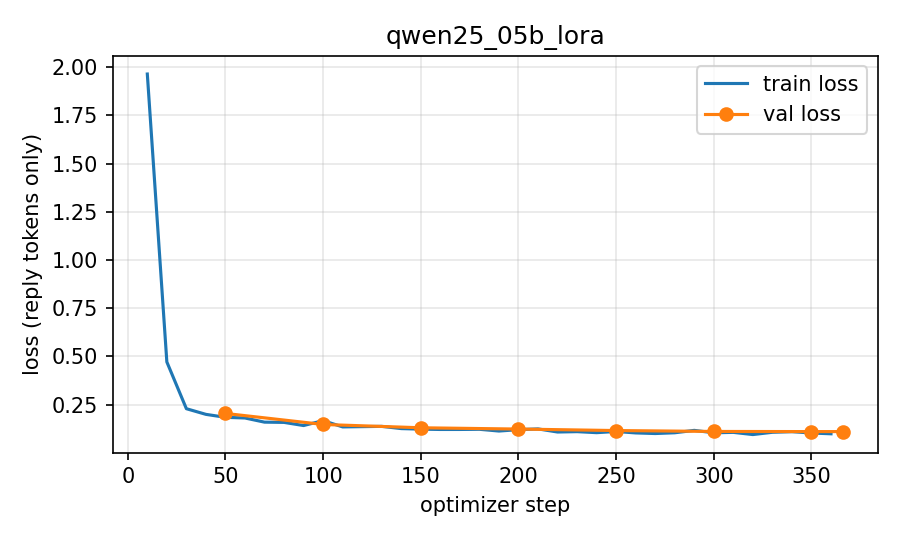

In [22]:
from IPython.display import Image, display
display(Image(str(cfg.run_dir / "figures" / "loss_curve.png")))

## 5. Save a small results zip to Drive (no checkpoints, no adapter) and list the run folder

In [23]:
from analogft.resultszip import make_results_zip
z = make_results_zip(cfg.run_dir)
rel = z.relative_to(paths.STORAGE_ROOT)
print(f"wrote {z}  ({z.stat().st_size / 1e6:.2f} MB)")
print(f"On drive.google.com open:  My Drive / {paths.PROJECT_NAME} / {rel.as_posix()}")
print(f"then download it and on the Mac run:  python scripts/import_results_zip.py ~/Downloads/{z.name}")
print()
for p in sorted(cfg.run_dir.rglob("*")):
    if p.is_file() and "checkpoints" not in p.parts:
        print(f"{p.stat().st_size / 1e6:8.2f} MB  {p.relative_to(cfg.run_dir)}")

wrote /content/drive/MyDrive/spice-verified-analog-finetuning/runs/phase3/qwen25_05b_lora_results.zip  (0.08 MB)
On drive.google.com open:  My Drive / spice-verified-analog-finetuning / runs/phase3/qwen25_05b_lora_results.zip
then download it and on the Mac run:  python scripts/import_results_zip.py ~/Downloads/qwen25_05b_lora_results.zip

    0.01 MB  adapter/README.md
    0.00 MB  adapter/adapter_config.json
   35.24 MB  adapter/adapter_model.safetensors
    0.00 MB  adapter/chat_template.jinja
   11.42 MB  adapter/tokenizer.json
    0.00 MB  adapter/tokenizer_config.json
    0.01 MB  adapter/training_args.bin
    0.00 MB  config.json
    0.00 MB  eval/base/subset/metrics.json
    0.06 MB  eval/base/subset/predictions.jsonl
    0.00 MB  eval/base/test/metrics.json
    0.15 MB  eval/base/test/predictions.jsonl
    0.00 MB  eval/base/val/metrics.json
    0.15 MB  eval/base/val/predictions.jsonl
    0.00 MB  eval/finetuned/subset/metrics.json
    0.07 MB  eval/finetuned/subset/predictio